In [1]:
import csv
from itertools import combinations
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


DATA_PATH = "baskets.csv"
MIN_SUPPORT = 0.01
SORT_BY = "support"  # support | lexicographic
THRESHOLDS = [0.01, 0.03, 0.05, 0.10, 0.15]
OUTPUT_DIR = Path("results")

OUTPUT_DIR.mkdir(exist_ok=True)

In [2]:
def load_baskets(path):
    baskets = []
    with open(path, encoding="cp1251", newline="") as file:
        for row in csv.reader(file):
            basket = set()
            for item in row:
                item = item.strip()
                if item:
                    basket.add(item)
            if basket:
                baskets.append(basket)
    return baskets


def apriori(baskets, min_support=0.01, sort_by="support"):
    if not 0 < min_support <= 1:
        raise ValueError("min_support must be in (0, 1]")
    if sort_by not in {"support", "lexicographic"}:
        raise ValueError("sort_by must be support or lexicographic")
    if not baskets:
        return []

    items = set()
    for basket in baskets:
        items.update(basket)

    candidates = []
    for item in sorted(items):
        candidates.append((item,))

    result = []
    while candidates:
        frequent = []
        for candidate in candidates:
            count = 0
            itemset = set(candidate)
            for basket in baskets:
                if itemset.issubset(basket):
                    count += 1

            support = count / len(baskets)
            if support >= min_support:
                frequent.append(candidate)
                result.append((candidate, count, support))

        candidates = []
        for left, right in combinations(frequent, 2):
            if left[:-1] != right[:-1]:
                continue
            candidate = left + (right[-1],)

            # Check all subsets
            valid = True
            for subset in combinations(candidate, len(candidate) - 1):
                if subset not in frequent:
                    valid = False
                    break
            if valid:
                candidates.append(candidate)

    if sort_by == "support":
        result.sort(key=lambda row: (-row[1], row[0]))
    else:
        result.sort(key=lambda row: row[0])
    return result

In [3]:
baskets = load_baskets(DATA_PATH)
rows = apriori(baskets, MIN_SUPPORT, SORT_BY)
patterns = pd.DataFrame(rows, columns=["items", "count", "support"])
display(patterns)

,items,count,support
0,"(минеральная вода,)",1788,0.238368
1,"(макароны,)",1410,0.187975
2,"(яйца,)",1348,0.179709
3,"(картофель-фри,)",1282,0.170911
4,"(шоколад,)",1229,0.163845
...,...,...,...
256,"(замороженные овощи, торт)",77,0.010265
257,"(минеральная вода, хлопья)",77,0.010265
258,"(говяжий фарш, минеральная вода, яйца)",76,0.010132
259,"(замороженные овощи, низкокалорийный йогурт)",76,0.010132


In [4]:
experiments = []
length_counts = []

for threshold in THRESHOLDS:
    start = perf_counter()
    rows = apriori(baskets, threshold, SORT_BY)
    seconds = perf_counter() - start
    experiments.append([threshold * 100, seconds, len(rows)])

    counts = {}
    for items, count, support in rows:
        length = len(items)
        counts[length] = counts.get(length, 0) + 1
    length_counts.append(counts)

summary = pd.DataFrame(experiments,
                       columns=["support_pct", "seconds", "itemsets"])
counts = pd.DataFrame(length_counts, index=summary["support_pct"])
counts = counts.fillna(0).astype(int).sort_index(axis=1)
display(summary, counts)

,support_pct,seconds,itemsets
0,1.0,4.024827,261
1,3.0,0.944197,55
2,5.0,0.560412,28
3,10.0,0.177559,7
4,15.0,0.169976,5


,1,2,3
support_pct,,,
1.0,74,170,17
3.0,36,19,0
5.0,25,3,0
10.0,7,0,0
15.0,5,0,0


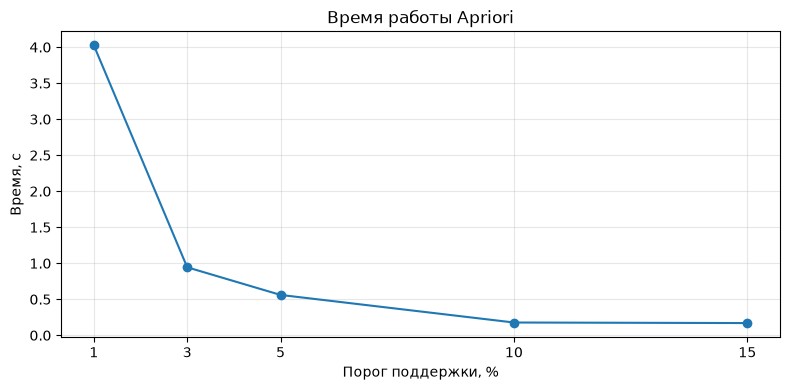

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(summary["support_pct"], summary["seconds"], marker="o")
plt.xlabel("Порог поддержки, %")
plt.ylabel("Время, с")
plt.title("Время работы Apriori")
plt.xticks(summary["support_pct"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "runtime.png", dpi=150)
plt.show()

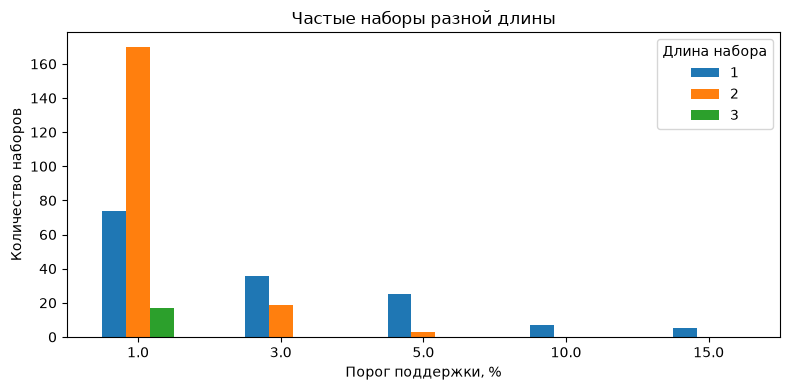

In [6]:
counts.plot.bar(figsize=(8, 4), rot=0)
plt.xlabel("Порог поддержки, %")
plt.ylabel("Количество наборов")
plt.title("Частые наборы разной длины")
plt.legend(title="Длина набора")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "lengths.png", dpi=150)
plt.show()